<class 'pandas.DataFrame'>
RangeIndex: 743914 entries, 0 to 743913
Data columns (total 18 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   adm0_id             743914 non-null  int64  
 1   adm0_name           743914 non-null  str    
 2   adm1_id             743914 non-null  int64  
 3   adm1_name           729965 non-null  str    
 4   mkt_id              743914 non-null  int64  
 5   mkt_name            743914 non-null  str    
 6   cm_id               743914 non-null  int64  
 7   cm_name             743914 non-null  str    
 8   cur_id              743914 non-null  int64  
 9   cur_name            743914 non-null  str    
 10  pt_id               743914 non-null  int64  
 11  pt_name             743914 non-null  str    
 12  um_id               743914 non-null  int64  
 13  um_name             743914 non-null  str    
 14  mp_month            743914 non-null  int64  
 15  mp_year             743914 non-null  int64  


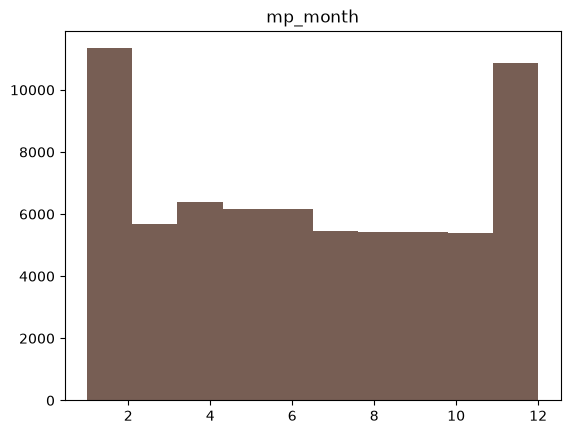

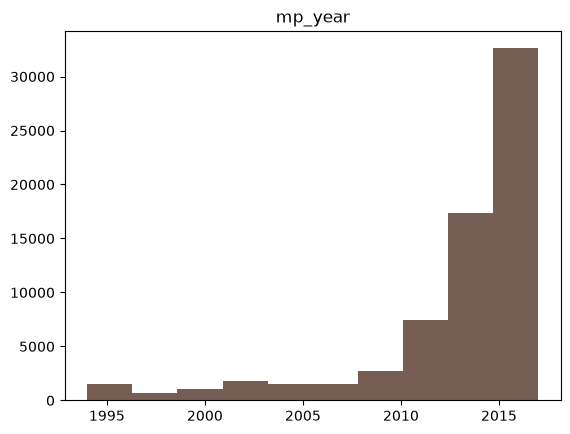

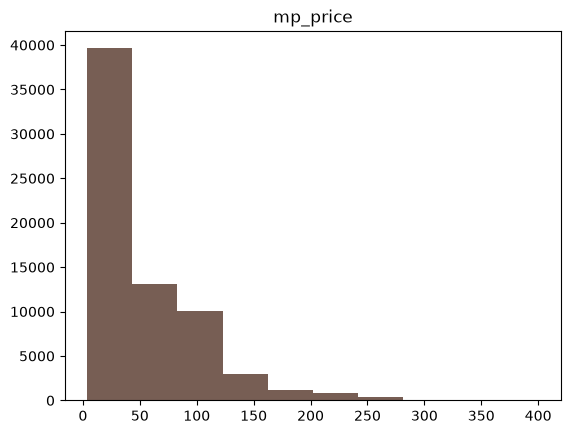

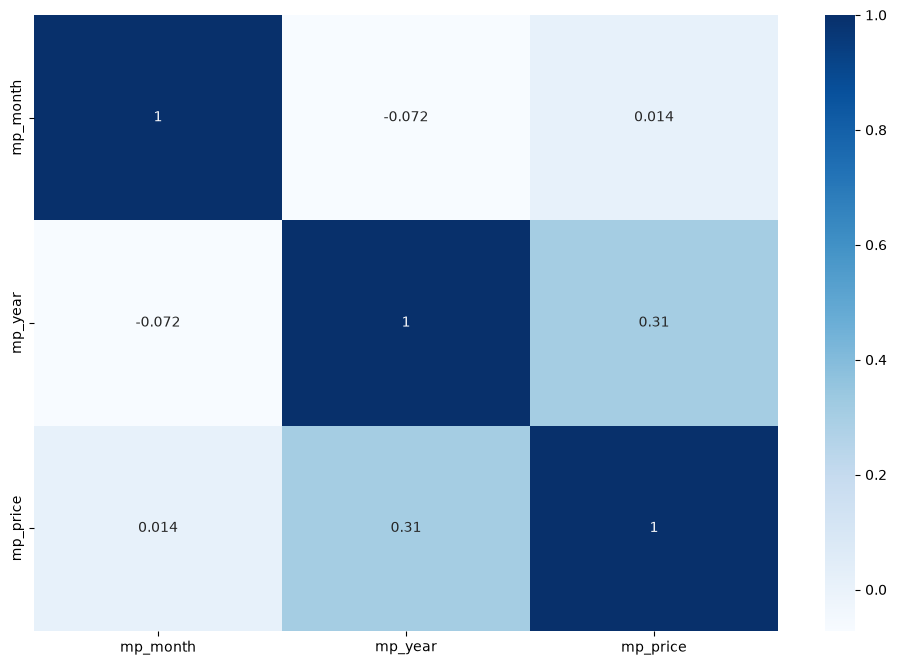

<class 'pandas.DataFrame'>
RangeIndex: 49351 entries, 0 to 49350
Columns: 118 entries, mp_year to mp_commoditysource_M/o Consumer Affairs, Food and Public Distribution, Government of India
dtypes: float64(117), int64(1)
memory usage: 44.4 MB


In [173]:
import matplotlib.pyplot as plt
%run ../notebooks/food_price_preprocessing.ipynb
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [174]:
def evaluate_model(model, x_test, y_test, model_name):
    y_pred = model.predict(x_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)*100

    print(f"===== {model_name} =====")
    print(f"MAE : {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R2   : {r2:.4f}")

    #scatter
    plt.gca().set_facecolor("#F3EEEC")
    plt.scatter(y_test, y_pred,color="#775E54")
    plt.plot([y_test.min(), y_test.max()], 
             [y_test.min(), y_test.max()], 
             color="#E6B3B8",
             linestyle='--',
             linewidth=3)
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(f"Actual vs Predicted Values ({model_name})")
    plt.show()

    return {"Model": model_name, "MAE": mae, "RMSE": rmse, "R2": r2}


k =  1  →  Validation RMSE = 9.3868
k =  3  →  Validation RMSE = 7.5967
k =  5  →  Validation RMSE = 7.3582
k =  7  →  Validation RMSE = 7.4612
k =  9  →  Validation RMSE = 7.7510
k = 11  →  Validation RMSE = 7.9993
k = 13  →  Validation RMSE = 8.4459
k = 15  →  Validation RMSE = 8.7382
k = 17  →  Validation RMSE = 9.0796
k = 19  →  Validation RMSE = 9.5300
k = 21  →  Validation RMSE = 9.8567
k = 23  →  Validation RMSE = 10.3268
k = 25  →  Validation RMSE = 10.9202
k = 27  →  Validation RMSE = 11.4552
k = 29  →  Validation RMSE = 11.9412


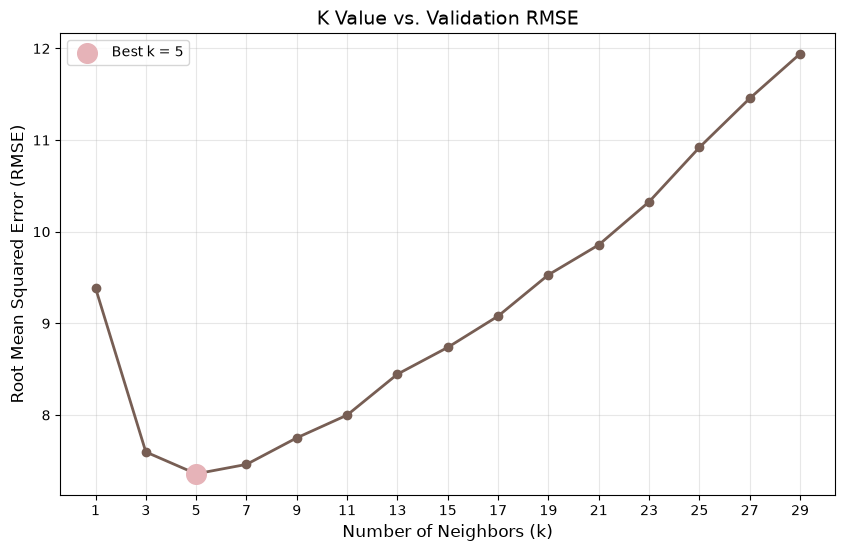

In [ ]:
k_values = [] 
val_errors = [] 
for k in range(1, 31, 2): 
    knn_model = KNeighborsRegressor(n_neighbors=k)
    knn_model.fit(x_train, y_train)
    
    y_pred_validation = knn_model.predict(x_validation)
    rmse = root_mean_squared_error(y_validation, y_pred_validation)
    
    k_values.append(k)
    val_errors.append(rmse)
    
    print(f"k = {k:2d}  →  Validation RMSE = {rmse:.4f}")

k = k_values[val_errors.index(min(val_errors))]

plt.figure(figsize=(10, 6))
plt.plot(k_values, val_errors, marker='o', linestyle='-', color='#775E54', linewidth=2)

plt.scatter([k], [min(val_errors)], 
            color='#E6B3B8', s=200, zorder=5, 
            label=f'Best k = {k}')

plt.title('K Value vs. Validation RMSE', fontsize=14)
plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('Root Mean Squared Error (RMSE)', fontsize=12)
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [176]:
linear_model = LinearRegression()
knn_model = KNeighborsRegressor(n_neighbors=k)

In [177]:
linear_model.fit(x_train, y_train)
knn_model.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


===== Linear Regression =====
MAE : 9.6284
RMSE: 14.9058
R2   : 90.3731


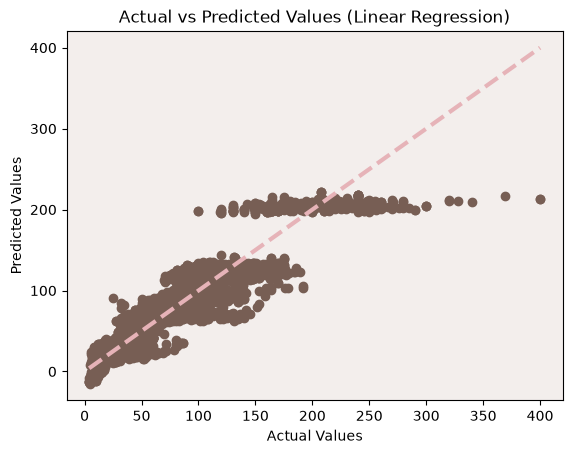

===== KNN Regressor =====
MAE : 3.7977
RMSE: 7.7191
R2   : 97.4183


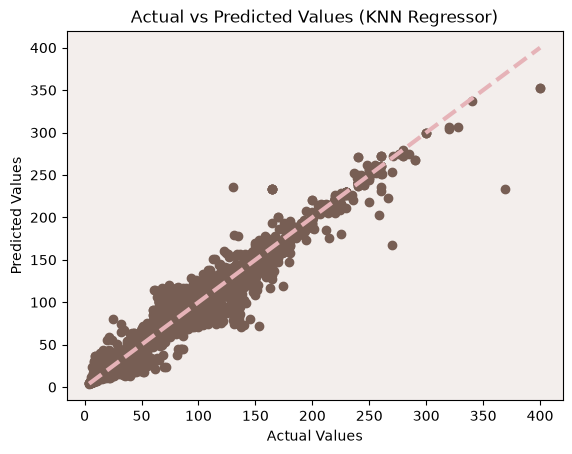

In [178]:
linear_eva = evaluate_model(linear_model, x_test, y_test, "Linear Regression")
knn_eva = evaluate_model(knn_model, x_test, y_test, "KNN Regressor")